## Dataset Load

In [12]:
import ast
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import softmax
from sklearn.metrics import mean_absolute_error, precision_score, recall_score, r2_score, roc_auc_score

panecho = pd.read_csv(r'results\echoQual_inference\panecho_EXAMPLE.csv')
echoprime = pd.read_csv(r'results\echoQual_inference\echoprime_EXAMPLE.csv')
ground_truth = pd.read_csv(r'results\echoQual_inference\ground_truth_EXAMPLE.csv')
view_ident = pd.read_csv(r'results\echoQual_inference\view_identification_EXAMPLE.csv')
demographics = pd.read_csv(r'results\echoQual_inference\patient_demographics_EXAMPLE.csv')
quality_pred = pd.read_csv(r'results\echoQual_inference\inference_predictions_EXAMPLE_calidad_1.csv')

In [13]:
synthetic_patient_ids = [f'ECHO_{i}' for i in range(4, 14)]
view_options = ['PSAX', 'PLAX', 'A2C', 'A3C', 'A4C', 'A5C', 'other']
quality_cycle = ['bad', 'normal', 'good', 'bad', 'normal', 'good', 'bad', 'normal', 'good', 'normal']
rng = np.random.default_rng(42)

def extract_patient_id_from_path(path):
    return str(path).replace('\\', '/').split('/')[-2]

def build_synthetic_path(patient_id, video_idx):
    return fr'..\echo\{patient_id}\synthetic_video_{video_idx:02d}.mp4'

def quality_logits_for_label(label):
    logits = {
        'bad': [3.5, 0.2, -1.5],
        'normal': [-1.0, 3.5, 0.0],
        'good': [-1.5, 0.3, 3.5],
    }
    return str(logits[label])

def sample_row(df):
    return df.sample(n=1, replace=True, random_state=int(rng.integers(0, 1_000_000))).iloc[0].copy()

# Keep this cell idempotent if it is re-run.
panecho = panecho[~panecho['path'].apply(extract_patient_id_from_path).isin(synthetic_patient_ids)].copy()
echoprime = echoprime[~echoprime['path'].apply(extract_patient_id_from_path).isin(synthetic_patient_ids)].copy()
view_ident = view_ident[~view_ident['path'].apply(extract_patient_id_from_path).isin(synthetic_patient_ids)].copy()
quality_pred = quality_pred[~quality_pred['path'].apply(extract_patient_id_from_path).isin(synthetic_patient_ids)].copy()
ground_truth = ground_truth[~ground_truth['patient_id'].isin(synthetic_patient_ids)].copy()
demographics = demographics[~demographics['patient_id'].isin(synthetic_patient_ids)].copy()

panecho_templates = panecho.copy()
echoprime_templates = echoprime.copy()
ground_truth_templates = ground_truth.copy()
demographics_templates = demographics.copy()

new_panecho_rows = []
new_echoprime_rows = []
new_view_rows = []
new_quality_rows = []
new_ground_truth_rows = []
new_demographics_rows = []

for patient_id, quality_label in zip(synthetic_patient_ids, quality_cycle):
    gt_row = sample_row(ground_truth_templates)
    gt_row['patient_id'] = patient_id
    new_ground_truth_rows.append(gt_row)

    demo_row = sample_row(demographics_templates)
    demo_row['patient_id'] = patient_id
    demo_row['year_of_study'] = int(rng.integers(2018, 2025))
    demo_row['age'] = int(rng.integers(35, 86))
    demo_row['sex'] = str(rng.choice(['Male', 'Female']))
    demo_row['imc'] = float(np.round(rng.uniform(18.0, 34.0), 2))
    new_demographics_rows.append(demo_row)

    for video_idx in range(1, 11):
        synthetic_path = build_synthetic_path(patient_id, video_idx)

        panecho_row = sample_row(panecho_templates)
        panecho_row['path'] = synthetic_path
        new_panecho_rows.append(panecho_row)

        echoprime_row = sample_row(echoprime_templates)
        echoprime_row['path'] = synthetic_path
        if 'video_id' in echoprime_row.index:
            echoprime_row['video_id'] = f'SYNTH_{patient_id}_{video_idx:02d}'
        new_echoprime_rows.append(echoprime_row)

        new_view_rows.append({
            'path': synthetic_path,
            'view': str(rng.choice(view_options)),
        })

        new_quality_rows.append({
            'path': synthetic_path,
            'fname': synthetic_path.replace('\\', '/').split('/')[-1],
            'quality': quality_logits_for_label(quality_label),
        })

panecho = pd.concat([panecho, pd.DataFrame(new_panecho_rows)], ignore_index=True)
echoprime = pd.concat([echoprime, pd.DataFrame(new_echoprime_rows)], ignore_index=True)
view_ident = pd.concat([view_ident, pd.DataFrame(new_view_rows)], ignore_index=True)
quality_pred = pd.concat([quality_pred, pd.DataFrame(new_quality_rows)], ignore_index=True)
ground_truth = pd.concat([ground_truth, pd.DataFrame(new_ground_truth_rows)], ignore_index=True)
demographics = pd.concat([demographics, pd.DataFrame(new_demographics_rows)], ignore_index=True)

video_df = quality_pred.merge(view_ident, on='path', how='left')
video_df['patient_id'] = video_df['path'].apply(extract_patient_id_from_path)
video_df


,Unnamed: 0_x,path,fname,quality,Unnamed: 0_y,view,patient_id
0,0.0,..\echo\ECHO_1\1.2.826.0.1.3680043.2.135.73865...,1.2.826.0.1.3680043.2.135.738651.68951324.7.17...,"[-1.033998966217041, 0.6184679269790649, 0.026...",0.0,A3C,ECHO_1
1,1.0,..\echo\ECHO_1\1.2.826.0.1.3680043.2.135.73865...,1.2.826.0.1.3680043.2.135.738651.68951324.7.17...,"[-1.704994559288025, 0.7010875344276428, 0.911...",1.0,A2C,ECHO_1
2,2.0,..\echo\ECHO_1\1.2.826.0.1.3680043.2.135.73865...,1.2.826.0.1.3680043.2.135.738651.68951324.7.17...,"[0.394212543964386, 0.6401153802871704, -1.412...",2.0,A4C,ECHO_1
3,3.0,..\echo\ECHO_1\1.2.826.0.1.3680043.2.135.73865...,1.2.826.0.1.3680043.2.135.738651.68951324.7.17...,"[1.4762012958526611, 0.4506734311580658, -2.34...",3.0,A3C,ECHO_1
4,4.0,..\echo\ECHO_1\1.2.826.0.1.3680043.2.135.73865...,1.2.826.0.1.3680043.2.135.738651.68951324.7.17...,"[1.9497514963150024, -0.05845397338271141, -2....",4.0,A2C,ECHO_1
...,...,...,...,...,...,...,...
168,NaN,..\echo\ECHO_13\synthetic_video_06.mp4,synthetic_video_06.mp4,"[-1.0, 3.5, 0.0]",NaN,other,ECHO_13
169,NaN,..\echo\ECHO_13\synthetic_video_07.mp4,synthetic_video_07.mp4,"[-1.0, 3.5, 0.0]",NaN,A5C,ECHO_13
170,NaN,..\echo\ECHO_13\synthetic_video_08.mp4,synthetic_video_08.mp4,"[-1.0, 3.5, 0.0]",NaN,other,ECHO_13
171,NaN,..\echo\ECHO_13\synthetic_video_09.mp4,synthetic_video_09.mp4,"[-1.0, 3.5, 0.0]",NaN,A3C,ECHO_13


In [14]:
# Remove view == 'other'
quality_videos = video_df[video_df['view'] != 'other'].copy()

# Process quality labels: softmax + argmax (0: bad, 1: normal, 2: good)
def get_quality_label(quality_val):
    """Get quality label from softmax + argmax"""
    # Parse quality if it's a string representation of a list
    if isinstance(quality_val, str):
        quality_val = ast.literal_eval(quality_val)
    
    quality_array = np.array(quality_val, dtype=float)
    probs = softmax(quality_array)
    label = np.argmax(probs)
    return label

quality_videos['quality_label'] = quality_videos['quality'].apply(get_quality_label)

# Voting at patient level
def vote_quality(group):
    """
    Vote quality at patient level:
    - bad vs (normal+good): if more bad -> bad, else continue
    - normal vs good: if more normal -> normal, else -> good
    """
    labels = group['quality_label'].values
    
    # Count each label
    bad_count = np.sum(labels == 0)
    normal_count = np.sum(labels == 1)
    good_count = np.sum(labels == 2)
    
    # First level: bad vs (normal+good)
    if bad_count > (normal_count + good_count):
        return 0  # bad
    
    # If normal+good is equal or more, distinguish between normal and good
    if normal_count > good_count:
        return 1  # normal
    else:  # good_count >= normal_count
        return 2  # good

quality_patient = quality_videos.groupby('patient_id').apply(vote_quality).reset_index()
quality_patient.columns = ['patient_id', 'quality_label']

# Map numeric labels to quality names
quality_map = {0: 'bad', 1: 'normal', 2: 'good'}
quality_patient['quality_study'] = quality_patient['quality_label'].map(quality_map)

quality_patient

e:\25366074H\AppData\Local\Temp\ipykernel_1964\1629350544.py:42: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  quality_patient = quality_videos.groupby('patient_id').apply(vote_quality).reset_index()


,patient_id,quality_label,quality_study
0,ECHO_1,1,normal
1,ECHO_10,0,bad
2,ECHO_11,1,normal
3,ECHO_12,2,good
4,ECHO_13,1,normal
5,ECHO_2,0,bad
6,ECHO_3,2,good
7,ECHO_4,0,bad
8,ECHO_5,1,normal
9,ECHO_6,2,good


## EchoQuality Study Level
- Total distribution
- EchoQuality vs:
    - Sex
    - Year
    - Age
    - BMI


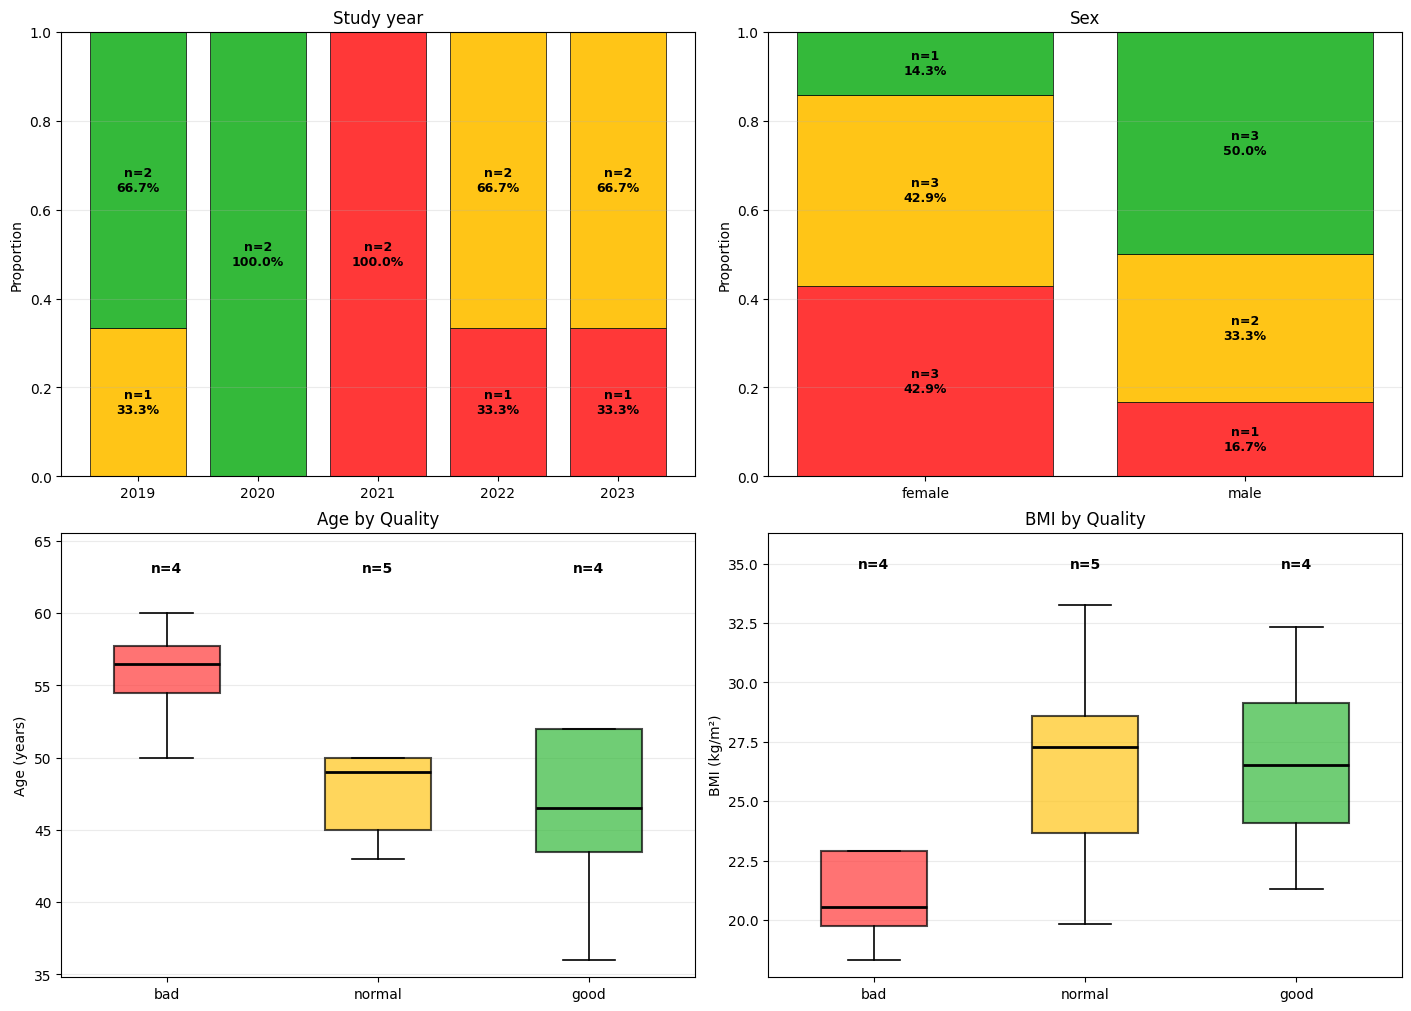

In [15]:
palette = {'bad': '#ff3838', 'normal': '#ffc517', 'good': '#34b93a'}
quality_col = 'calidad_label'
from sklearn.metrics import precision_score, recall_score

quality_order = ['bad', 'normal', 'good']
colors = palette

df = demographics.merge(
    quality_patient[['patient_id', 'quality_study']],
    on='patient_id',
    how='inner'
).rename(columns={'quality_study': 'calidad_label'})

def stacked_quality_bars(ax, df_in, group_col, title, group_order=None, rotate_xticks=0):
    d = df_in[[group_col, quality_col, 'patient_id']].dropna().copy()
    d[group_col] = d[group_col].astype(str)

    counts = pd.crosstab(d[group_col], d[quality_col])
    counts = counts.reindex(columns=quality_order, fill_value=0)

    if group_order is None:
        counts = counts.sort_index()
    else:
        counts = counts.reindex([str(x) for x in group_order]).dropna(how='all').fillna(0)

    props = counts.div(counts.sum(axis=1), axis=0).fillna(0)

    bottom = np.zeros(len(props))
    x = np.arange(len(props))
    for q in quality_order:
        vals = props[q].to_numpy()
        ax.bar(x, vals, bottom=bottom, color=colors[q], label=q, edgecolor='black', linewidth=0.5)

        for i, val in enumerate(vals):
            n_label = int(counts.iloc[i][q])
            if n_label > 0 and val > 0:
                ax.text(
                    x[i],
                    bottom[i] + val / 2,
                    f'n={n_label}\n{val * 100:.1f}%',
                    ha='center',
                    va='center',
                    fontsize=9,
                    fontweight='bold'
                )

        bottom += vals

    ax.set_title(title)
    ax.set_xticks(x)
    ax.set_xticklabels(props.index.tolist(), rotation=rotate_xticks, ha='right' if rotate_xticks else 'center')
    ax.set_ylim(0, 1)
    ax.set_ylabel('Proportion')
    ax.grid(axis='y', alpha=0.25)

def draw_box(ax, data, counts, title, ylabel, quality_order, palette):
    plot_order = [q for q, arr in zip(quality_order, data) if len(arr) > 0]
    plot_data = [arr for arr in data if len(arr) > 0]

    box = ax.boxplot(
        plot_data,
        tick_labels=plot_order,
        patch_artist=True,
        showfliers=False,
        widths=0.5,
        medianprops=dict(color='black', linewidth=2),
        boxprops=dict(edgecolor='black', linewidth=1.5),
        whiskerprops=dict(color='black', linewidth=1.2),
        capprops=dict(color='black', linewidth=1.2)
    )

    for patch, q in zip(box['boxes'], plot_order):
        patch.set_facecolor(palette[q])
        patch.set_alpha(0.7)

    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.grid(axis='y', alpha=0.25)
    y0, y1 = ax.get_ylim()
    y_text = y1 - 0.06 * (y1 - y0)
    for i, q in enumerate(plot_order, start=1):
        ax.text(i, y_text + 0.05*y_text, f'n={counts[q]}', ha='center', va='bottom', fontsize=10, fontweight='bold')
    ax.set_ylim(top=y_text + 0.1*y_text)
# -------- prepare df_plot --------
df_plot = df.copy()

df_plot['year'] = pd.to_numeric(df_plot['year_of_study'], errors='coerce')
df_plot['sex'] = df_plot['sex'].astype(str).str.strip().str.lower()

df_plot['age'] = pd.to_numeric(df_plot['age'], errors='coerce')
df_plot['imc'] = pd.to_numeric(df_plot['imc'], errors='coerce')

edad_data, imc_data = [], []
edad_counts, imc_counts = {}, {}
for q in quality_order:
    dqq = df_plot[df_plot[quality_col] == q]

    edad_counts[q] = dqq.loc[dqq['age'].notna(), 'patient_id'].nunique()
    edad_vals = dqq['age'].to_numpy(float)
    edad_vals = edad_vals[~np.isnan(edad_vals)]
    edad_data.append(edad_vals)

    imc_counts[q] = dqq.loc[dqq['imc'].notna(), 'patient_id'].nunique()
    imc_vals = dqq['imc'].to_numpy(float)
    imc_vals = imc_vals[~np.isnan(imc_vals)]
    imc_data.append(imc_vals)

fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)

years = sorted(df_plot['year'].dropna().unique().astype(int).tolist())
rotate = 45 if len(years) > 8 else 0
stacked_quality_bars(axes[0, 0], df_plot, 'year', 'Study year', group_order=years, rotate_xticks=rotate)
stacked_quality_bars(axes[0, 1], df_plot, 'sex', 'Sex')

draw_box(
    axes[1, 0], edad_data, edad_counts,
    title='Age by Quality',
    ylabel='Age (years)',
    quality_order=quality_order,
    palette=palette
)

draw_box(
    axes[1, 1], imc_data, imc_counts,
    title='BMI by Quality',
    ylabel='BMI (kg/m²)',
    quality_order=quality_order,
    palette=palette
)

plt.show()


## EchoQuality vs AI Models
- Measures
- Diseases

### Group PanEcho

In [16]:
panecho['patient_id'] = panecho['path'].apply(extract_patient_id_from_path)

def parse_array_string(value):
    """Convert an array-like string or numeric value into a list of floats."""
    if pd.isna(value) or value == '' or value is None:
        return None
    
    value_str = str(value).strip()
    
    # Handle strings that represent arrays enclosed in brackets.
    if value_str.startswith('[') and value_str.endswith(']'):
        try:
            # Remove brackets and split on whitespace.
            value_str = value_str[1:-1].strip()
            # Convert values, including scientific notation.
            parts = value_str.split()
            return [float(p) for p in parts if p]
        except (ValueError, IndexError):
            return None
    
    # Handle plain numeric values.
    try:
        return [float(value_str)]
    except ValueError:
        return None
    
def mean_of_list_v2(series_of_values):
    """
    Compute the element-wise mean across multiple lists for one patient_id.
    Example: [[a,b,c], [e,f,g]] -> [(a+e)/2, (b+f)/2, (c+g)/2]
    Return a list with the mean at each position.
    """
    all_arrays = []
    
    for value in series_of_values:
        parsed = parse_array_string(value)
        if parsed is not None:
            all_arrays.append(parsed)
    
    if not all_arrays:
        return np.nan
    
    # If there is only one array, return it unchanged.
    if len(all_arrays) == 1:
        return all_arrays[0]
    
    # Compute the element-wise mean by aligning values by position.
    max_len = max(len(arr) for arr in all_arrays)
    
    # Pad shorter arrays with NaN values.
    arrays_padded = []
    for arr in all_arrays:
        if len(arr) < max_len:
            arr = arr + [np.nan] * (max_len - len(arr))
        arrays_padded.append(arr)
    
    # Compute the mean for each position.
    element_means = np.nanmean(np.array(arrays_padded), axis=0)
    
    # Return the result as a list.
    return element_means.tolist()

panecho_study = panecho.groupby('patient_id').agg({
    'pericardial-effusion': 'mean',
    'EF': 'mean',
    'GLS': 'mean',
    'LVEDV': 'mean',
    'LVESV': 'mean',
    'LVSV': 'mean',
    'LVSize': lambda x: mean_of_list_v2(x),
    'LVWallThickness-increased-any': 'mean',
    'LVWallThickness-increased-modsev': 'mean',
    'LVSystolicFunction': lambda x: mean_of_list_v2(x),
    'LVWallMotionAbnormalities': 'mean',
    'IVSd': 'mean',
    'LVPWd': 'mean',
    'LVIDs': 'mean',
    'LVIDd': 'mean',
    'LVOTDiam': 'mean',
    'LVDiastolicFunction': lambda x: mean_of_list_v2(x),
    'E|EAvg': 'mean',
    'RVSP': 'mean',
    'RVSize': lambda x: mean_of_list_v2(x),
    'RVSystolicFunction': 'mean',
    'RVIDd': 'mean',
    'TAPSE': 'mean',
    'RVSVel': 'mean',
    'LASize': lambda x: mean_of_list_v2(x),
    'LAIDs2D': 'mean',
    'LAVol': 'mean',
    'RASize': 'mean',
    'RADimensionM-L(cm)': 'mean',
    'AVStructure': 'mean',
    'AVStenosis': lambda x: mean_of_list_v2(x),
    'AVPkVel(m|s)': 'mean',
    'AVRegurg': lambda x: mean_of_list_v2(x),
    'LVOT20mmHg': 'mean',
    'MVStenosis': 'mean',
    'MVRegurgitation': lambda x: mean_of_list_v2(x),
    'TVRegurgitation': lambda x: mean_of_list_v2(x),
    'TVPkGrad': 'mean',
    'RAP-8-or-higher': 'mean',
    'AORoot': 'mean',
}).reset_index()

panecho_study

,patient_id,pericardial-effusion,EF,GLS,LVEDV,LVESV,LVSV,LVSize,LVWallThickness-increased-any,LVWallThickness-increased-modsev,...,AVStenosis,AVPkVel(m|s),AVRegurg,LVOT20mmHg,MVStenosis,MVRegurgitation,TVRegurgitation,TVPkGrad,RAP-8-or-higher,AORoot
0,ECHO_1,0.035175,54.500115,15.454002,113.676090,54.086250,59.515903,"[0.0699943904239535, 0.057915210615302325, 0.8...",0.459901,0.081137,...,"[0.19578590343720934, 0.6929869318604653, 0.11...",2.035629,"[0.23299559534883718, 0.06969574348837206, 0.6...",0.002861,0.099507,"[0.3518107767441861, 0.21909738441860468, 0.42...","[0.3304510476744186, 0.1794449506976744, 0.490...",28.277765,0.190923,3.265838
1,ECHO_10,0.027557,52.882336,15.053248,124.409379,58.512267,65.733816,"[0.13789723562000003, 0.051714274676000004, 0....",0.461906,0.071581,...,"[0.17249793064, 0.6902692340000001, 0.13723285...",2.030608,"[0.25448486000000003, 0.08700831499999999, 0.6...",0.002377,0.128476,"[0.355891262, 0.241173751, 0.4029349730000001]","[0.31769286500000005, 0.251902662, 0.430404470...",31.534333,0.303157,3.364377
2,ECHO_11,0.053421,57.141402,15.989830,92.377208,40.646676,51.576119,"[0.03873325066, 0.011188469859900001, 0.950078...",0.463467,0.055392,...,"[0.14737111084, 0.8090148770000001, 0.04361402...",1.779441,"[0.189556751, 0.059066492000000005, 0.751376761]",0.002443,0.086833,"[0.393628087, 0.202668985, 0.4037029370000001]","[0.36434922, 0.29678898200000003, 0.338861796]",33.390177,0.231060,3.236832
3,ECHO_12,0.075664,49.818377,13.141905,131.498230,68.899878,62.709712,"[0.08054314511999999, 0.10966888774900001, 0.8...",0.553105,0.111658,...,"[0.29654758500000006, 0.561218497, 0.142233932...",2.114623,"[0.314150461, 0.10739272500000001, 0.578456805...",0.004022,0.134820,"[0.41589053100000006, 0.274375268, 0.309734197...","[0.362374388, 0.24895418699999997, 0.388671444]",29.704769,0.285530,3.428861
4,ECHO_13,0.044111,47.766019,14.265117,126.293254,66.468575,59.688129,"[0.12958256031999998, 0.0778272155452, 0.79259...",0.431793,0.068123,...,"[0.1846919525, 0.7691417599999999, 0.046166278...",1.783990,"[0.178698417, 0.05107992600000001, 0.770221674...",0.003225,0.092687,"[0.385185209, 0.174125886, 0.44068890200000005]","[0.30115125800000003, 0.106360206, 0.592488537]",27.315040,0.161942,3.281571
5,ECHO_2,0.052162,49.986270,13.878751,131.362608,66.677795,64.771294,"[0.15426653128407408, 0.09560984065781482, 0.7...",0.482424,0.075913,...,"[0.1677323026666666, 0.7827281374074074, 0.049...",1.730435,"[0.2205625744444445, 0.09543142962962962, 0.68...",0.002503,0.044043,"[0.36082178777777785, 0.18866897074074077, 0.4...","[0.3590001714814815, 0.13625608703703707, 0.50...",26.190097,0.159811,3.449172
6,ECHO_3,0.018833,46.564023,13.484479,123.307173,67.931793,55.352894,"[0.09232594666666666, 0.19020900333333332, 0.7...",0.329729,0.032441,...,"[0.19195449, 0.7692801333333333, 0.03876536000...",1.655101,"[0.2361244366666667, 0.05717309, 0.70670248333...",0.000682,0.075215,"[0.45684736, 0.37751471666666664, 0.1656379466...","[0.41711449000000006, 0.4542712566666666, 0.12...",39.305934,0.559277,3.418269
7,ECHO_4,0.097919,48.951263,13.148517,122.002931,62.686155,59.591066,"[0.13827337700000003, 0.040657321, 0.821069320...",0.429503,0.058673,...,"[0.1761637, 0.7572081079999999, 0.066628211999...",1.810456,"[0.19158175, 0.06183658400000001, 0.746581658]",0.002417,0.050378,"[0.370470327, 0.26009042700000007, 0.369439254]","[0.29361293, 0.16747080799999997, 0.5389162689...",25.470905,0.168483,3.309710
8,ECHO_5,0.053021,57.104093,14.243016,98.170301,43.191737,54.893202,"[0.04201278787, 0.013564980819, 0.944422259000...",0.679968,0.193576,...,"[0.23668357700000003, 0.609680794, 0.153635628...",2.266438,"[0.302991523, 0.106667132, 0.590341351]",0.005908,0.124141,"[0.461974664, 0.22734192699999997, 0.310683407]","[0.38346874900000005, 0.247462237, 0.369069025...",30.012066,0.253479,3.309945
9,ECHO_6,0.034450,48.568449,14.362407,125.357423,66.513641,59.117291,"[0.11871059614299999, 0.1362678079458, 0.74502...",0.4164

### Measures

In [17]:
metrics_to_eval = [
    'EF', 'GLS', 'LVEDV', 'LVESV', 'LVSV', 'IVSd', 'LVPWd', 'LVIDs', 'LVIDd',
    'LVOTDiam', 'E|EAvg', 'RVSP', 'RVIDd', 'TAPSE', 'RVSVel', 'LAIDs2D',
    'LAVol', 'RASize', 'AVPkVel(m|s)', 'AORoot'
]

quality_order = ['bad', 'normal', 'good']
n_bootstrap = 1000
rng = np.random.default_rng(42)

performance_df = (
    ground_truth
    .merge(panecho_study, on='patient_id', how='inner', suffixes=('_gt', '_pred'))
    .merge(quality_patient[['patient_id', 'quality_study']], on='patient_id', how='left')
)

performance_df

def bootstrap_metric_ci(y_true, y_pred, metric_name, n_boot=1000, rng=None):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    valid_mask = (~np.isnan(y_true)) & (~np.isnan(y_pred))
    y_true = y_true[valid_mask]
    y_pred = y_pred[valid_mask]

    if len(y_true) == 0:
        return np.nan, np.nan, np.nan, 0

    if metric_name == 'mae':
        point_estimate = mean_absolute_error(y_true, y_pred)
    elif metric_name == 'r2':
        if len(y_true) < 2 or np.isclose(np.var(y_true), 0.0):
            return np.nan, np.nan, np.nan, len(y_true)
        point_estimate = r2_score(y_true, y_pred)
    else:
        raise ValueError(f'Unsupported metric: {metric_name}')

    if len(y_true) == 1:
        return point_estimate, np.nan, np.nan, 1

    boot_values = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        boot_true = y_true[idx]
        boot_pred = y_pred[idx]

        if metric_name == 'mae':
            boot_values.append(mean_absolute_error(boot_true, boot_pred))
        else:
            if len(np.unique(boot_true)) < 2 or np.isclose(np.var(boot_true), 0.0):
                continue
            boot_values.append(r2_score(boot_true, boot_pred))

    if len(boot_values) == 0:
        return point_estimate, np.nan, np.nan, len(y_true)

    ci_low, ci_high = np.percentile(boot_values, [2.5, 97.5])
    return point_estimate, ci_low, ci_high, len(y_true)

results = []

for metric in metrics_to_eval:
    gt_col = f'{metric}_gt'
    pred_col = f'{metric}_pred'

    if gt_col not in performance_df.columns or pred_col not in performance_df.columns:
        continue

    metric_df = performance_df[['patient_id', 'quality_study', gt_col, pred_col]].copy()
    metric_df[gt_col] = pd.to_numeric(metric_df[gt_col], errors='coerce')
    metric_df[pred_col] = pd.to_numeric(metric_df[pred_col], errors='coerce')

    for quality in quality_order:
        subset = metric_df[metric_df['quality_study'] == quality].copy()
        subset = subset.dropna(subset=[gt_col, pred_col])

        y_true = subset[gt_col].to_numpy(dtype=float)
        y_pred = subset[pred_col].to_numpy(dtype=float)

        r2_value, r2_ci_low, r2_ci_high, n_samples = bootstrap_metric_ci(
            y_true, y_pred, metric_name='r2', n_boot=n_bootstrap, rng=rng
        )
        mae_value, mae_ci_low, mae_ci_high, _ = bootstrap_metric_ci(
            y_true, y_pred, metric_name='mae', n_boot=n_bootstrap, rng=rng
        )

        results.append({
            'metric': metric,
            'model': 'panecho',
            'quality': quality,
            'n_patients': n_samples,
            'r2': r2_value,
            'r2_ci_low': r2_ci_low,
            'r2_ci_high': r2_ci_high,
            'mae': mae_value,
            'mae_ci_low': mae_ci_low,
            'mae_ci_high': mae_ci_high,
        })

performance_by_metric_quality = pd.DataFrame(results)
performance_by_metric_quality


,metric,model,quality,n_patients,r2,r2_ci_low,r2_ci_high,mae,mae_ci_low,mae_ci_high
0,EF,panecho,bad,4,-35.240541,-610.248547,-21.696365,11.546670,7.097107,15.996234
1,EF,panecho,normal,5,-286.090308,-646.944746,-209.690515,9.475641,6.931593,12.210075
2,EF,panecho,good,4,-614.399509,-850.953790,-359.450983,12.303037,8.220135,15.363764
3,GLS,panecho,bad,4,-0.542029,-78.837612,-0.364541,5.717341,4.423316,7.011366
4,GLS,panecho,normal,5,0.135584,-0.903542,0.415630,3.737049,2.838410,4.603247
5,GLS,panecho,good,4,-0.042744,-0.642448,0.235937,3.509508,2.097548,4.835825
6,LVEDV,panecho,bad,4,-0.364178,-20.858031,-0.161350,14.854677,4.099516,25.609838
7,LVEDV,panecho,normal,5,-5.229552,-14.083260,-1.403597,33.341627,13.927475,52.755778
8,LVEDV,panecho,good,4,-0.187108,-1.710937,-0.016366,13.005189,6.274937,22.020126
9,LVESV,panecho,bad,4,0.356361,-99.877838,0.495376,16.084833,10.296328,20.188025


In [18]:
echoprime_study = echoprime.copy()
echoprime_study['patient_id'] = (
    echoprime_study['path']
    .astype(str)
    .str.replace('\\', '/', regex=False)
    .str.split('/')
    .str[-2]
)
echoprime_study['ejection_fraction'] = pd.to_numeric(
    echoprime_study['ejection_fraction'], errors='coerce'
)
echoprime_study = (
    echoprime_study
    .groupby('patient_id', as_index=False)
    .agg({'ejection_fraction': 'mean'})
)

echoprime_performance_df = (
    ground_truth[['patient_id', 'EF']]
    .merge(echoprime_study, on='patient_id', how='inner')
    .merge(quality_patient[['patient_id', 'quality_study']], on='patient_id', how='left')
)

echoprime_results = []

for quality in quality_order:
    subset = echoprime_performance_df[
        echoprime_performance_df['quality_study'] == quality
    ].copy()
    subset['EF'] = pd.to_numeric(subset['EF'], errors='coerce')
    subset['ejection_fraction'] = pd.to_numeric(
        subset['ejection_fraction'], errors='coerce'
    )
    subset = subset.dropna(subset=['EF', 'ejection_fraction'])

    y_true = subset['EF'].to_numpy(dtype=float)
    y_pred = subset['ejection_fraction'].to_numpy(dtype=float)

    r2_value, r2_ci_low, r2_ci_high, n_samples = bootstrap_metric_ci(
        y_true, y_pred, metric_name='r2', n_boot=n_bootstrap, rng=rng
    )
    mae_value, mae_ci_low, mae_ci_high, _ = bootstrap_metric_ci(
        y_true, y_pred, metric_name='mae', n_boot=n_bootstrap, rng=rng
    )

    echoprime_results.append({
        'metric': 'EF',
        'model': 'echoprime',
        'quality': quality,
        'n_patients': n_samples,
        'r2': r2_value,
        'r2_ci_low': r2_ci_low,
        'r2_ci_high': r2_ci_high,
        'mae': mae_value,
        'mae_ci_low': mae_ci_low,
        'mae_ci_high': mae_ci_high,
    })

echoprime_ef_performance_by_quality = pd.DataFrame(echoprime_results)
echoprime_ef_performance_by_quality

,metric,model,quality,n_patients,r2,r2_ci_low,r2_ci_high,mae,mae_ci_low,mae_ci_high
0,EF,echoprime,bad,4,-5.257059,-78.592034,-3.207193,4.437847,2.043148,7.023372
1,EF,echoprime,normal,5,-62.652343,-113.623604,-49.466760,4.647883,4.109442,5.154301
2,EF,echoprime,good,4,-34.499811,-47.141264,-15.096302,2.960118,1.886162,3.674091


### Diseases

In [19]:
quality_order = ['bad', 'normal', 'good']
n_bootstrap = 1000
rng = np.random.default_rng(42)

disease_mappings = {
    'pericardial-effusion': {
        'ground_truth': 'pericardial-effusion',
        'panecho': 'pericardial-effusion',
        'echoprime': 'pericardial_effusion',
    },
    'AVStenosis': {
        'ground_truth': 'AVStenosis',
        'panecho': 'AVStenosis',
        'echoprime': 'aortic_stenosis',
    },
    'AVRegurg': {
        'ground_truth': 'AVRegurg',
        'panecho': 'AVRegurg',
        'echoprime': 'aortic_regurgitation',
    },
    'MVStenosis': {
        'ground_truth': 'MVStenosis',
        'panecho': 'MVStenosis',
        'echoprime': 'mitral_stenosis',
    },
    'MVRegurgitation': {
        'ground_truth': 'MVRegurgitation',
        'panecho': 'MVRegurgitation',
        'echoprime': 'mitral_regurgitation',
    },
    'TVRegurgitation': {
        'ground_truth': 'TVRegurgitation',
        'panecho': 'TVRegurgitation',
        'echoprime': 'tricuspid_valve_regurgitation',
    },
}

def parse_prediction_value(value):
    if isinstance(value, (list, tuple, np.ndarray)):
        return np.asarray(value, dtype=float)
    if pd.isna(value):
        return np.asarray([], dtype=float)
    value_str = str(value).strip()
    if value_str.startswith('[') and value_str.endswith(']'):
        inner = value_str[1:-1].replace(',', ' ').strip()
        if not inner:
            return np.asarray([], dtype=float)
        try:
            return np.asarray([float(x) for x in inner.split() if x], dtype=float)
        except ValueError:
            return np.asarray([], dtype=float)
    numeric_value = pd.to_numeric(pd.Series([value]), errors='coerce').iloc[0]
    if pd.isna(numeric_value):
        return np.asarray([], dtype=float)
    return np.asarray([float(numeric_value)], dtype=float)

def to_binary_ground_truth(value):
    numeric_value = pd.to_numeric(pd.Series([value]), errors='coerce').iloc[0]
    if pd.isna(numeric_value):
        return np.nan
    return int(numeric_value > 0)

def to_probability_score(value):
    arr = parse_prediction_value(value)
    arr = arr[~np.isnan(arr)]
    if len(arr) == 0:
        return np.nan
    if len(arr) == 1:
        return float(arr[0])
    return float(np.max(arr[1:]))

def compute_precision_recall(y_true, y_score, threshold=0.5):
    y_true = np.asarray(y_true, dtype=float)
    y_score = np.asarray(y_score, dtype=float)
    valid_mask = (~np.isnan(y_true)) & (~np.isnan(y_score))
    y_true = y_true[valid_mask]
    y_score = y_score[valid_mask]

    if len(y_true) == 0:
        return np.nan, np.nan

    y_pred = (y_score >= threshold).astype(int)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    return float(precision), float(recall)

def bootstrap_auc_ci(y_true, y_score, metric_name, model_name, quality_name, n_boot=1000, rng=None):
    y_true = np.asarray(y_true, dtype=float)
    y_score = np.asarray(y_score, dtype=float)
    valid_mask = (~np.isnan(y_true)) & (~np.isnan(y_score))
    y_true = y_true[valid_mask]
    y_score = y_score[valid_mask]

    if len(y_true) == 0:
        print(f'AUC not computed for {model_name} | {metric_name} | {quality_name}: no valid samples after dropping NaNs.')
        return np.nan, np.nan, np.nan, len(y_true)

    if len(np.unique(y_true)) < 2:
        print(
            f'AUC not computed for {model_name} | {metric_name} | {quality_name}: '
            f'ground truth has only one class ({sorted(np.unique(y_true).tolist())}).'
        )
        return np.nan, np.nan, np.nan, len(y_true)

    point_estimate = roc_auc_score(y_true, y_score)
    boot_values = []

    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        boot_true = y_true[idx]
        boot_score = y_score[idx]
        if len(np.unique(boot_true)) < 2:
            continue
        boot_values.append(roc_auc_score(boot_true, boot_score))

    if len(boot_values) == 0:
        print(
            f'AUC CI not computed for {model_name} | {metric_name} | {quality_name}: '
            'all bootstrap resamples contained a single class.'
        )
        return point_estimate, np.nan, np.nan, len(y_true)

    ci_low, ci_high = np.percentile(boot_values, [2.5, 97.5])
    return point_estimate, ci_low, ci_high, len(y_true)

panecho_disease_df = panecho_study.copy()
panecho_disease_df = panecho_disease_df.merge(
    quality_patient[['patient_id', 'quality_study']], on='patient_id', how='left'
)

echoprime_disease_df = echoprime.copy()
echoprime_disease_df['patient_id'] = echoprime_disease_df['path'].apply(extract_patient_id_from_path)
echoprime_agg_map = {
    cols['echoprime']: 'mean'
    for cols in disease_mappings.values()
    if cols['echoprime'] in echoprime_disease_df.columns
}
for col in echoprime_agg_map:
    echoprime_disease_df[col] = pd.to_numeric(echoprime_disease_df[col], errors='coerce')
echoprime_disease_df = echoprime_disease_df.groupby('patient_id', as_index=False).agg(echoprime_agg_map)
echoprime_disease_df = echoprime_disease_df.merge(
    quality_patient[['patient_id', 'quality_study']], on='patient_id', how='left'
)

disease_auc_rows = []

for disease_name, cols in disease_mappings.items():
    gt_col = cols['ground_truth']
    panecho_col = cols['panecho']
    echoprime_col = cols['echoprime']

    if gt_col not in ground_truth.columns:
        continue
    if panecho_col not in panecho_disease_df.columns:
        continue
    if echoprime_col not in echoprime_disease_df.columns:
        continue

    panecho_eval = ground_truth[['patient_id', gt_col]].rename(
        columns={gt_col: 'y_true_raw'}
    ).merge(
        panecho_disease_df[['patient_id', 'quality_study', panecho_col]].rename(
            columns={panecho_col: 'y_score_raw'}
        ),
        on='patient_id',
        how='inner'
    )
    panecho_eval['y_true'] = panecho_eval['y_true_raw'].apply(to_binary_ground_truth)
    panecho_eval['y_score'] = panecho_eval['y_score_raw'].apply(to_probability_score)

    echoprime_eval = ground_truth[['patient_id', gt_col]].rename(
        columns={gt_col: 'y_true_raw'}
    ).merge(
        echoprime_disease_df[['patient_id', 'quality_study', echoprime_col]].rename(
            columns={echoprime_col: 'y_score_raw'}
        ),
        on='patient_id',
        how='inner'
    )
    echoprime_eval['y_true'] = echoprime_eval['y_true_raw'].apply(to_binary_ground_truth)
    echoprime_eval['y_score'] = echoprime_eval['y_score_raw'].apply(to_probability_score)

    for quality in quality_order:
        panecho_subset = panecho_eval[panecho_eval['quality_study'] == quality].copy()
        panecho_auc, panecho_ci_low, panecho_ci_high, panecho_n = bootstrap_auc_ci(
            panecho_subset['y_true'].to_numpy(dtype=float),
            panecho_subset['y_score'].to_numpy(dtype=float),
            metric_name=disease_name,
            model_name='panecho',
            quality_name=quality,
            n_boot=n_bootstrap,
            rng=rng,
        )
        panecho_precision, panecho_recall = compute_precision_recall(
            panecho_subset['y_true'].to_numpy(dtype=float),
            panecho_subset['y_score'].to_numpy(dtype=float),
        )
        disease_auc_rows.append({
            'model': 'panecho',
            'disease': disease_name,
            'quality': quality,
            'n_patients': panecho_n,
            'auc': panecho_auc,
            'auc_ci_low': panecho_ci_low,
            'auc_ci_high': panecho_ci_high,
            'precision': panecho_precision,
            'recall': panecho_recall,
        })

        echoprime_subset = echoprime_eval[echoprime_eval['quality_study'] == quality].copy()
        echoprime_auc, echoprime_ci_low, echoprime_ci_high, echoprime_n = bootstrap_auc_ci(
            echoprime_subset['y_true'].to_numpy(dtype=float),
            echoprime_subset['y_score'].to_numpy(dtype=float),
            metric_name=disease_name,
            model_name='echoprime',
            quality_name=quality,
            n_boot=n_bootstrap,
            rng=rng,
        )
        echoprime_precision, echoprime_recall = compute_precision_recall(
            echoprime_subset['y_true'].to_numpy(dtype=float),
            echoprime_subset['y_score'].to_numpy(dtype=float),
        )
        disease_auc_rows.append({
            'model': 'echoprime',
            'disease': disease_name,
            'quality': quality,
            'n_patients': echoprime_n,
            'auc': echoprime_auc,
            'auc_ci_low': echoprime_ci_low,
            'auc_ci_high': echoprime_ci_high,
            'precision': echoprime_precision,
            'recall': echoprime_recall,
        })

disease_auc_by_quality = pd.DataFrame(disease_auc_rows)
disease_auc_by_quality


,model,disease,quality,n_patients,auc,auc_ci_low,auc_ci_high,precision,recall
0,panecho,pericardial-effusion,bad,4,1.000000,1.0,1.000000,0.00,0.0
1,echoprime,pericardial-effusion,bad,4,1.000000,1.0,1.000000,0.00,0.0
2,panecho,pericardial-effusion,normal,5,0.333333,0.0,1.000000,0.00,0.0
3,echoprime,pericardial-effusion,normal,5,0.416667,0.0,1.000000,0.00,0.0
4,panecho,pericardial-effusion,good,4,0.333333,0.0,1.000000,0.00,0.0
5,echoprime,pericardial-effusion,good,4,0.333333,0.0,1.000000,0.00,0.0
6,panecho,AVStenosis,bad,4,1.000000,1.0,1.000000,0.50,1.0
7,echoprime,AVStenosis,bad,4,0.500000,0.0,1.000000,0.00,0.0
8,panecho,AVStenosis,normal,5,0.333333,0.0,1.000000,0.60,1.0
9,echoprime,AVStenosis,normal,5,0.333333,0.0,1.000000,0.00,0.0
